# 08 — Phase 2: METR-LA Graph Attention Network

## Goal
Move beyond independent sensor models. Build a fixed distance-weighted graph from the official DCRNN METR-LA road-distance table, then train a spatial Graph Attention Network (GAT) on the timestamped METR-LA speed series.

## Fair setup
The official graph sensor order must exactly match the 207 CSV speed columns. Use the same chronological 70/10/20 split, 25-minute maximum input history, 5/15/30/60-minute targets, and zero-as-missing target mask as the AML baselines. Standardize using training timestamps only. Since the supplied data contains speed only, this GAT is speed-only; flow and occupancy are not invented.

## 1. Load observations, official graph inputs, and training-only scaler

In [1]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
GRAPH = DATA / 'sensor_graph'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
PREDICTIONS = ROOT / 'results' / 'predictions'
for folder in [FIG, METRICS, PREDICTIONS]:
    folder.mkdir(parents=True, exist_ok=True)

traffic = pd.read_csv(DATA / 'METR-LA.csv', index_col=0, parse_dates=True)
traffic.index.name = 'timestamp'
traffic.columns = traffic.columns.astype(str)
sensor_ids = (GRAPH / 'graph_sensor_ids.txt').read_text().strip().split(',')
assert traffic.columns.tolist() == sensor_ids, 'METR-LA traffic columns and official graph sensor order differ.'
distance = pd.read_csv(GRAPH / 'distances_la_2012.csv', dtype={'from': str, 'to': str})
assert {'from', 'to', 'cost'}.issubset(distance.columns)
assert traffic.index.is_monotonic_increasing and not traffic.index.has_duplicates
assert traffic.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=5)).all()

observed = traffic.apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float32)
observed[observed <= 0] = np.nan
train_end = int(len(traffic) * .70)
validation_end = int(len(traffic) * .80)
train_mean = np.nanmean(observed[:train_end], axis=0).astype(np.float32)
train_std = np.nanstd(observed[:train_end], axis=0).astype(np.float32)
train_std[train_std < 1e-6] = 1.0
filled = pd.DataFrame(observed).ffill().to_numpy(dtype=np.float32)
filled = np.where(np.isfinite(filled), filled, train_mean[None, :])
speed_scaled = (filled - train_mean[None, :]) / train_std[None, :]
print(f'Loaded {len(sensor_ids)} aligned sensors and {len(traffic):,} five-minute observations.')
print(f'Train-only scaler means/stds: {train_mean.mean():.3f} / {train_std.mean():.3f}')
print(f'Observed targets: {np.isfinite(observed).mean():.1%}; missing/zero targets remain masked.')
print('PyTorch device:', 'mps' if torch.backends.mps.is_available() else 'cpu')

Loaded 207 aligned sensors and 34,272 five-minute observations.
Train-only scaler means/stds: 58.615 / 10.108
Observed targets: 91.9%; missing/zero targets remain masked.
PyTorch device: mps


## 2. Construct and inspect the fixed road-distance adjacency

Fixed graph: 207 nodes, 1313 undirected sensor links, average degree 12.7.
Adjacency is symmetrized road-distance connectivity, not a known traffic-flow direction.


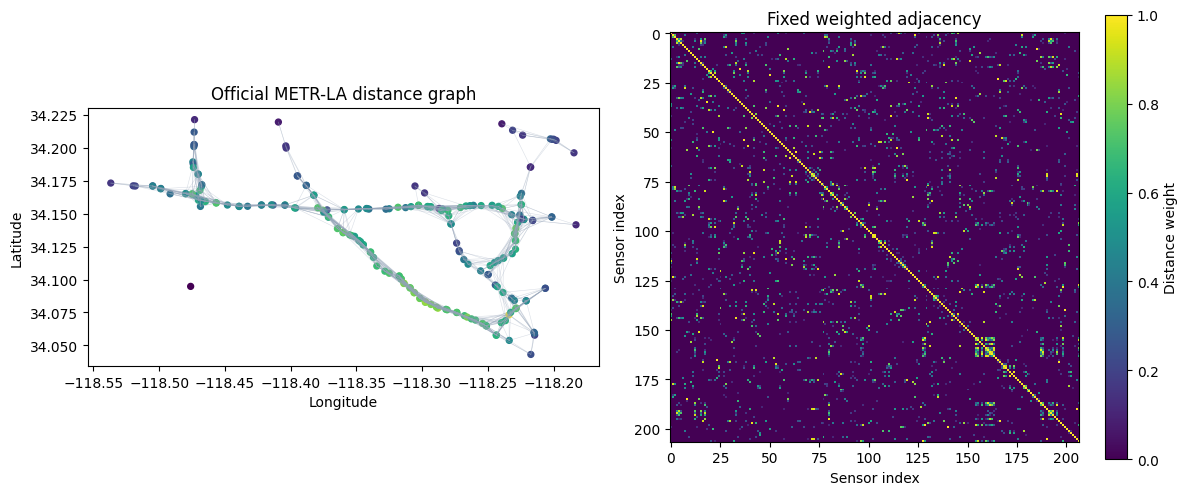

In [2]:
sensor_index = {sensor_id: i for i, sensor_id in enumerate(sensor_ids)}
distance_matrix = np.full((len(sensor_ids), len(sensor_ids)), np.inf, dtype=np.float32)
valid_edges = distance[distance['from'].isin(sensor_index) & distance['to'].isin(sensor_index)]
for row in valid_edges.itertuples(index=False):
    distance_matrix[sensor_index[row[0]], sensor_index[row[1]]] = float(row[2])
finite_distances = distance_matrix[np.isfinite(distance_matrix)]
distance_std = finite_distances.std()
adjacency = np.exp(-np.square(distance_matrix / distance_std)).astype(np.float32)
adjacency[~np.isfinite(adjacency)] = 0
adjacency[adjacency < .1] = 0
adjacency = np.maximum(adjacency, adjacency.T)
np.fill_diagonal(adjacency, 1.0)
assert np.isfinite(adjacency).all() and np.allclose(adjacency, adjacency.T)
np.savetxt(METRICS / 'metr_la_distance_adjacency.csv', adjacency, delimiter=',', fmt='%.6f')
edge_count = int(np.triu(adjacency > 0, k=1).sum())
degree = (adjacency > 0).sum(axis=1) - 1
print(f'Fixed graph: {len(sensor_ids)} nodes, {edge_count} undirected sensor links, average degree {degree.mean():.1f}.')
print('Adjacency is symmetrized road-distance connectivity, not a known traffic-flow direction.')

locations = pd.read_csv(GRAPH / 'graph_sensor_locations.csv')
locations['sensor_id'] = locations['sensor_id'].astype(str)
locations = locations.set_index('sensor_id').loc[sensor_ids].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, j in zip(*np.where(np.triu(adjacency > 0, k=1))):
    axes[0].plot([locations.loc[i, 'longitude'], locations.loc[j, 'longitude']],
                 [locations.loc[i, 'latitude'], locations.loc[j, 'latitude']],
                 color='#94a3b8', lw=.4, alpha=.35)
axes[0].scatter(locations['longitude'], locations['latitude'], c=degree, cmap='viridis', s=18)
axes[0].set(title='Official METR-LA distance graph', xlabel='Longitude', ylabel='Latitude', aspect='equal')
image = axes[1].imshow(adjacency, cmap='viridis', interpolation='nearest')
fig.colorbar(image, ax=axes[1], label='Distance weight')
axes[1].set(title='Fixed weighted adjacency', xlabel='Sensor index', ylabel='Sensor index')
fig.tight_layout()
fig.savefig(FIG / '25_metr_la_fixed_adjacency.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 3. Create chronological windows and masked multi-horizon targets

Each input covers six five-minute observations (current speed through 25 minutes ago), matching the baselines' maximum history. Training windows remain in the first 70% of timestamps; validation and test windows come only after their respective chronological boundaries.

In [3]:
horizons = {5: 1, 15: 3, 30: 6, 60: 12}
horizon_steps = np.array(list(horizons.values()), dtype=np.int32)
origins = np.arange(5, len(traffic) - horizon_steps.max(), dtype=np.int32)
target_indices = origins[:, None] + horizon_steps[None, :]
target_values = observed[target_indices].transpose(0, 2, 1)
target_scaled = (target_values - train_mean[None, :, None]) / train_std[None, :, None]
target_mask = np.isfinite(target_scaled)
target_scaled = np.where(target_mask, target_scaled, 0).astype(np.float32)
train_rows = np.flatnonzero(target_indices[:, -1] < train_end)
validation_rows = np.flatnonzero((origins >= train_end) & (target_indices[:, -1] < validation_end))
test_rows = np.flatnonzero(origins >= validation_end)
minute = (traffic.index.hour * 60 + traffic.index.minute).to_numpy()
weekday = traffic.index.dayofweek.to_numpy()
time_features = np.column_stack([
    np.sin(2 * np.pi * minute / 1440), np.cos(2 * np.pi * minute / 1440),
    np.sin(2 * np.pi * weekday / 7), np.cos(2 * np.pi * weekday / 7)
]).astype(np.float32)
print(f'Train windows: {len(train_rows):,} | validation windows: {len(validation_rows):,} | test windows: {len(test_rows):,}')
print('Output horizons:', list(horizons), 'minutes; target mask keeps measured speeds only.')

Train windows: 23,973 | validation windows: 3,415 | test windows: 6,843
Output horizons: [5, 15, 30, 60] minutes; target mask keeps measured speeds only.


## 4. Define a small distance-masked Graph Attention Network

In [4]:
class GraphAttentionLayer(nn.Module):
    def __init__(self, input_size, hidden_size, adjacency):
        super().__init__()
        self.projection = nn.Linear(input_size, hidden_size, bias=False)
        self.source_attention = nn.Parameter(torch.empty(hidden_size))
        self.target_attention = nn.Parameter(torch.empty(hidden_size))
        self.norm = nn.LayerNorm(hidden_size)
        nn.init.xavier_uniform_(self.projection.weight)
        nn.init.normal_(self.source_attention, std=.1)
        nn.init.normal_(self.target_attention, std=.1)
        self.register_buffer('edge_bias', torch.where(
            adjacency > 0, adjacency.clamp_min(1e-8).log(), torch.full_like(adjacency, -1e9)
        ))

    def forward(self, features):
        hidden = F.elu(self.projection(features))
        source = (hidden * self.source_attention).sum(dim=-1, keepdim=True)
        target = (hidden * self.target_attention).sum(dim=-1).unsqueeze(1)
        logits = F.leaky_relu(source + target, negative_slope=.2) + self.edge_bias
        attention = torch.softmax(logits, dim=-1)
        messages = torch.bmm(attention, hidden)
        return F.elu(self.norm(hidden + messages))

class TrafficGAT(nn.Module):
    def __init__(self, adjacency, input_size=10, hidden_size=32, output_size=4):
        super().__init__()
        self.gat = GraphAttentionLayer(input_size, hidden_size, adjacency)
        self.dropout = nn.Dropout(.15)
        self.head = nn.Sequential(nn.Linear(hidden_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, output_size))

    def forward(self, features):
        return self.head(self.dropout(self.gat(features)))

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
adjacency_tensor = torch.tensor(adjacency, dtype=torch.float32, device=device)
model = TrafficGAT(adjacency_tensor).to(device)
print(model)
print('Device:', device, '| trainable parameters:', sum(parameter.numel() for parameter in model.parameters()))

TrafficGAT(
  (gat): GraphAttentionLayer(
    (projection): Linear(in_features=10, out_features=32, bias=False)
    (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (dropout): Dropout(p=0.15, inplace=False)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=4, bias=True)
  )
)
Device: mps | trainable parameters: 1636


## 5. Train with masked loss and chronological validation

In [5]:
def make_batch(rows):
    t = origins[rows]
    history = np.stack([speed_scaled[t - lag] for lag in range(5, -1, -1)], axis=-1)
    clock = np.broadcast_to(time_features[t, None, :], (len(t), len(sensor_ids), 4))
    x = np.concatenate([history, clock], axis=-1)
    return (
        torch.tensor(x, dtype=torch.float32, device=device),
        torch.tensor(target_scaled[rows], dtype=torch.float32, device=device),
        torch.tensor(target_mask[rows], dtype=torch.bool, device=device)
    )

@torch.no_grad()
def evaluate_loss(rows):
    model.eval()
    total_loss = total_count = 0.0
    for start in range(0, len(rows), 32):
        batch_rows = rows[start:start + 32]
        x, y, mask = make_batch(batch_rows)
        prediction = model(x)
        total_loss += (((prediction - y) ** 2) * mask).sum().item()
        total_count += mask.sum().item()
    return total_loss / total_count

optimizer = torch.optim.Adam(model.parameters(), lr=.003, weight_decay=1e-5)
batch_size = 32
epochs = 10
patience = 3
best_validation = np.inf
best_state = None
stale_epochs = 0
history = []
rng = np.random.default_rng(42)
for epoch in range(epochs):
    model.train()
    epoch_loss = count = 0.0
    shuffled = rng.permutation(train_rows)
    for start in range(0, len(shuffled), batch_size):
        rows = shuffled[start:start + batch_size]
        x, y, mask = make_batch(rows)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(x)
        loss = (((prediction - y) ** 2) * mask).sum() / mask.sum().clamp_min(1)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        optimizer.step()
        epoch_loss += loss.item() * mask.sum().item()
        count += mask.sum().item()
    validation_loss = evaluate_loss(validation_rows)
    history.append({'epoch': epoch + 1, 'train_masked_mse': epoch_loss / count, 'validation_masked_mse': validation_loss})
    print(f"Epoch {epoch + 1:02d}: train MSE={epoch_loss / count:.4f}, validation MSE={validation_loss:.4f}")
    if validation_loss < best_validation:
        best_validation = validation_loss
        best_state = copy.deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= patience:
            print('Early stopping: validation loss did not improve.')
            break
model.load_state_dict(best_state)
pd.DataFrame(history).to_csv(METRICS / 'metr_la_gat_training_history.csv', index=False)
print(f'Best validation masked MSE: {best_validation:.4f}')

Epoch 01: train MSE=0.4713, validation MSE=0.4363


Epoch 02: train MSE=0.4368, validation MSE=0.4292


Epoch 03: train MSE=0.4303, validation MSE=0.4220


Epoch 04: train MSE=0.4261, validation MSE=0.4249


Epoch 05: train MSE=0.4231, validation MSE=0.4262


Epoch 06: train MSE=0.4217, validation MSE=0.4314
Early stopping: validation loss did not improve.
Best validation masked MSE: 0.4220


## 6. Test forecasts, masked horizon metrics, and peak/off-peak scores

Peak is defined in advance as weekdays 07:00–09:59 and 16:00–18:59. Off-peak includes every other test timestamp, including weekends. Scores use only observed targets and the identical test origins/horizons as the tree baselines.

In [6]:
@torch.no_grad()
def predict_rows(rows):
    model.eval()
    batches = []
    for start in range(0, len(rows), 32):
        x, _, _ = make_batch(rows[start:start + 32])
        batches.append(model(x).cpu().numpy())
    return np.concatenate(batches, axis=0)

prediction_scaled = predict_rows(test_rows)
prediction = prediction_scaled * train_std[None, :, None] + train_mean[None, :, None]
actual = observed[target_indices[test_rows]].transpose(0, 2, 1)
test_target_times = target_indices[test_rows]
target_timestamps = traffic.index.to_series().iloc[test_target_times.ravel()].to_numpy().reshape(test_target_times.shape)
target_hours = traffic.index.hour.to_numpy()[target_indices[test_rows]]
target_weekdays = traffic.index.dayofweek.to_numpy()[target_indices[test_rows]]
peak_mask = (target_weekdays < 5) & (((target_hours >= 7) & (target_hours < 10)) | ((target_hours >= 16) & (target_hours < 19)))
period_masks = {'All': np.ones_like(peak_mask, dtype=bool), 'Peak': peak_mask, 'Off-peak': ~peak_mask}
gat_scores = []
for h_idx, minutes in enumerate(horizons):
    for period, period_mask in period_masks.items():
        valid = np.isfinite(actual[:, :, h_idx]) & period_mask[:, h_idx, None]
        error = actual[:, :, h_idx][valid] - prediction[:, :, h_idx][valid]
        gat_scores.append({
            'dataset': 'METR-LA', 'model': 'GAT', 'period': period,
            'horizon_minutes': minutes,
            'MAE': np.mean(np.abs(error)),
            'MAPE_percent': np.mean(np.abs(error) / actual[:, :, h_idx][valid]) * 100,
            'RMSE': np.sqrt(np.mean(error ** 2)),
            'valid_test_values': int(valid.sum())
        })
gat_metrics = pd.DataFrame(gat_scores)
gat_metrics.to_csv(METRICS / 'metr_la_gat_metrics.csv', index=False)
display(gat_metrics.round(3))

baseline_rf = pd.read_csv(METRICS / 'metr_la_baseline_metrics.csv')
baseline_xgb = pd.read_csv(METRICS / 'metr_la_xgboost_metrics.csv')
for baseline in [baseline_rf, baseline_xgb]:
    baseline['period'] = 'All'
baseline_all = pd.concat([baseline_rf, baseline_xgb], ignore_index=True)
comparison_all = pd.concat([baseline_all, gat_metrics], ignore_index=True, sort=False)
comparison_all.to_csv(METRICS / 'metr_la_model_comparison.csv', index=False)
display(comparison_all[comparison_all['period'] == 'All'][['model', 'horizon_minutes', 'MAE', 'MAPE_percent', 'RMSE', 'valid_test_values']].round(3))
print('Detailed all/peak/off-peak comparison metrics are generated in notebook 07.')

,dataset,model,period,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values
0,METR-LA,GAT,All,5,2.879,7.206000,4.511,1244846
1,METR-LA,GAT,Peak,5,3.601,11.918000,5.618,250523
2,METR-LA,GAT,Off-peak,5,2.696,6.019000,4.187,994323
3,METR-LA,GAT,All,15,3.466,9.168000,5.830,1244834
4,METR-LA,GAT,Peak,15,4.737,15.852000,7.713,250523
5,METR-LA,GAT,Off-peak,15,3.146,7.484000,5.249,994311
6,METR-LA,GAT,All,30,4.087,11.434000,6.965,1244816
7,METR-LA,GAT,Peak,30,6.001,20.818001,9.487,250523
8,METR-LA,GAT,Off-peak,30,3.605,9.070000,6.169,994293
9,METR-LA,GAT,All,60,4.898,14.328000,8.227,1244780


,model,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values
0,Persistence,5,2.814,6.489,4.627,1244846
1,Random Forest,5,2.519,6.327,4.281,1244846
2,Persistence,15,3.499,8.612,6.418,1244834
3,Random Forest,15,3.119,8.431,5.702,1244834
4,Persistence,30,4.207,10.858,8.052,1244816
5,Random Forest,30,3.635,10.401,6.706,1244816
6,Persistence,60,5.381,14.535,10.345,1244780
7,Random Forest,60,4.192,12.623,7.657,1244780
8,XGBoost,5,2.554,6.435,4.326,1244846
9,XGBoost,15,3.239,8.846,5.873,1244834


Detailed all/peak/off-peak comparison metrics are generated in notebook 07.


## 7. Training curves, horizon comparison, and sample prediction

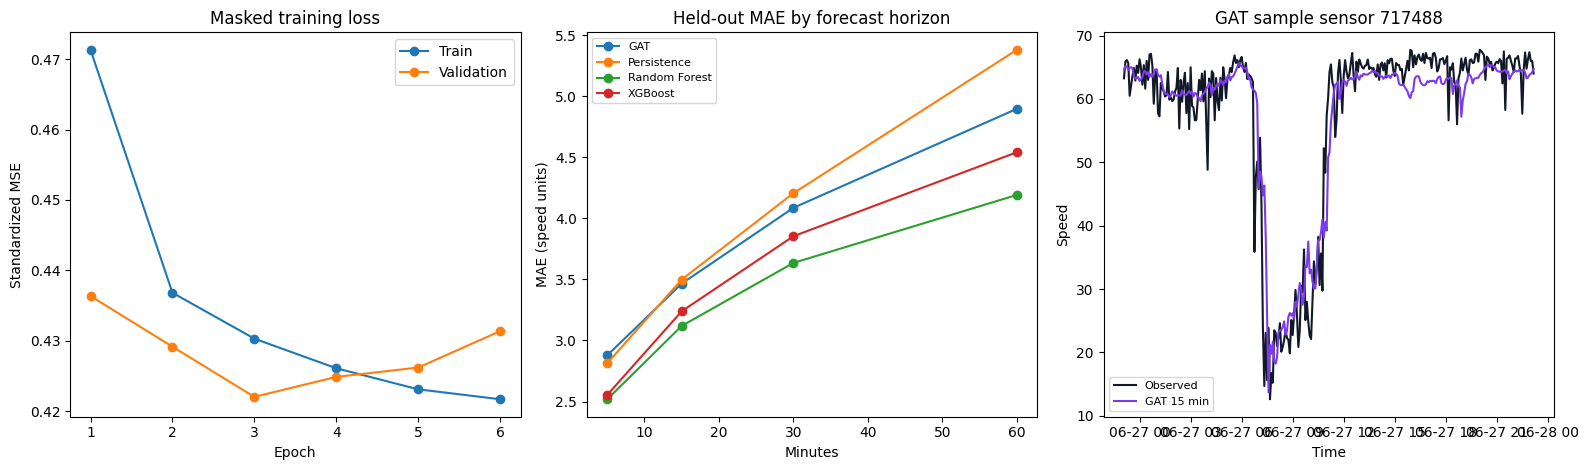

Saved GAT weights, metrics, sample forecast, and figure.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
training = pd.DataFrame(history)
axes[0].plot(training['epoch'], training['train_masked_mse'], marker='o', label='Train')
axes[0].plot(training['epoch'], training['validation_masked_mse'], marker='o', label='Validation')
axes[0].set(title='Masked training loss', xlabel='Epoch', ylabel='Standardized MSE')
axes[0].legend()
for model_name, group in comparison_all[comparison_all['period'] == 'All'].groupby('model'):
    axes[1].plot(group['horizon_minutes'], group['MAE'], marker='o', label=model_name)
axes[1].set(title='Held-out MAE by forecast horizon', xlabel='Minutes', ylabel='MAE (speed units)')
axes[1].legend(fontsize=8)
sample_idx = len(sensor_ids) // 2
sample_horizon_idx = list(horizons).index(15)
sample_timestamps = pd.to_datetime(target_timestamps[:, sample_horizon_idx])
sample_frame = pd.DataFrame({
    'timestamp': sample_timestamps,
    'actual_speed': actual[:, sample_idx, sample_horizon_idx],
    'predicted_speed_15min': prediction[:, sample_idx, sample_horizon_idx]
})
sample_frame.to_csv(PREDICTIONS / 'metr_la_gat_sample_sensor.csv', index=False)
sample_frame = sample_frame.dropna(subset=['actual_speed']).tail(288)
axes[2].plot(sample_frame['timestamp'], sample_frame['actual_speed'], label='Observed', color='#111827')
axes[2].plot(sample_frame['timestamp'], sample_frame['predicted_speed_15min'], label='GAT 15 min', color='#7c3aed')
axes[2].set(title=f'GAT sample sensor {sensor_ids[sample_idx]}', xlabel='Time', ylabel='Speed')
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / '26_metr_la_gat_training_and_forecasts.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved GAT weights, metrics, sample forecast, and figure.')
torch.save(model.cpu().state_dict(), METRICS / 'metr_la_gat_state_dict.pt')